In [379]:
#No terminal, uma vez: python -m pip install pandas numpy matplotlib seaborn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt

In [380]:
path = r"vendas.csv"

In [381]:

vendas = pd.read_csv(path, header=None, sep=';', names=['data', 'loja', 'produto', 'quantidade', 'preco_unitario'], encoding='latin1')

In [382]:
vendas

,data,loja,produto,quantidade,preco_unitario
0,01/09/2023,Loja A,Mouse,50.0,40.0
1,02/10/2023,Loja B,Teclado,32.0,55.0
2,03/10/2023,Loja A,Monitor,10.0,300.0
3,09/10/2023,Loja C,Fone,NaN,60.0


In [383]:
type(vendas)

pandas.DataFrame

In [384]:
vendas.columns = ['data', 'loja', 'produto', 'quantidade', 'preco_unitario']

In [385]:
vendas['data'] = pd.to_datetime(  vendas['data'],  format='%d/%m/%Y',  errors='coerce' )

In [386]:
vendas['data']

0   2023-09-01
1   2023-10-02
2   2023-10-03
3   2023-10-09
Name: data, dtype: datetime64[us]

In [387]:
faturamento = vendas['quantidade'] * vendas['preco_unitario']

In [388]:
vendas['faturamento'] = faturamento

In [389]:
vendas

,data,loja,produto,quantidade,preco_unitario,faturamento
0,2023-09-01,Loja A,Mouse,50.0,40.0,2000.0
1,2023-10-02,Loja B,Teclado,32.0,55.0,1760.0
2,2023-10-03,Loja A,Monitor,10.0,300.0,3000.0
3,2023-10-09,Loja C,Fone,NaN,60.0,NaN


In [390]:
vendas.info()

<class 'pandas.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   data            4 non-null      datetime64[us]
 1   loja            4 non-null      str           
 2   produto         4 non-null      str           
 3   quantidade      3 non-null      float64       
 4   preco_unitario  4 non-null      float64       
 5   faturamento     3 non-null      float64       
dtypes: datetime64[us](1), float64(3), str(2)
memory usage: 324.0 bytes


In [391]:
vendas.isnull().sum()

data              0
loja              0
produto           0
quantidade        1
preco_unitario    0
faturamento       1
dtype: int64

In [392]:
vendas.describe().round(2)

,data,quantidade,preco_unitario,faturamento
count,4,3.00,4.00,3.00
mean,2023-09-26 06:00:00,30.67,113.75,2253.33
min,2023-09-01 00:00:00,10.00,40.00,1760.00
25%,2023-09-24 06:00:00,21.00,51.25,1880.00
50%,2023-10-02 12:00:00,32.00,57.50,2000.00
75%,2023-10-04 12:00:00,41.00,120.00,2500.00
max,2023-10-09 00:00:00,50.00,300.00,3000.00
std,NaN,20.03,124.46,657.67


In [393]:
subsVarNull = pd.DataFrame(index=vendas.index)

for col in vendas.columns:
    s = vendas[col]

    if s.isna().any():
        if col != "faturamento" and pd.api.types.is_numeric_dtype(s):
            s = s.fillna(round(s.mean(), 2))

    subsVarNull[col] = s
    print(subsVarNull[col])

SubsFaturamento = subsVarNull['quantidade'] * subsVarNull['preco_unitario']
subsVarNull['faturamento'] = SubsFaturamento

0   2023-09-01
1   2023-10-02
2   2023-10-03
3   2023-10-09
Name: data, dtype: datetime64[us]
0    Loja A
1    Loja B
2    Loja A
3    Loja C
Name: loja, dtype: str
0       Mouse
1     Teclado
2     Monitor
3        Fone
Name: produto, dtype: str
0    50.00
1    32.00
2    10.00
3    30.67
Name: quantidade, dtype: float64
0     40.0
1     55.0
2    300.0
3     60.0
Name: preco_unitario, dtype: float64
0    2000.0
1    1760.0
2    3000.0
3       NaN
Name: faturamento, dtype: float64


In [394]:
subsVarNull 

,data,loja,produto,quantidade,preco_unitario,faturamento
0,2023-09-01,Loja A,Mouse,50.00,40.0,2000.0
1,2023-10-02,Loja B,Teclado,32.00,55.0,1760.0
2,2023-10-03,Loja A,Monitor,10.00,300.0,3000.0
3,2023-10-09,Loja C,Fone,30.67,60.0,1840.2


In [395]:
ordemLojas = vendas.groupby('loja')['faturamento'].sum().sort_values(ascending=False)
print(ordemLojas)

loja
Loja A    5000.0
Loja B    1760.0
Loja C       0.0
Name: faturamento, dtype: float64


In [396]:
ticketMedio = vendas.groupby('loja')['faturamento'].sum() / vendas.groupby('loja')['quantidade'].sum()
print(ticketMedio.round(2))

loja
Loja A    83.33
Loja B    55.00
Loja C      NaN
dtype: float64


In [397]:
ProdutosMaisVendidos = vendas.groupby('produto')['quantidade'].sum().sort_values(ascending=False)
print(ProdutosMaisVendidos)

produto
Mouse      50.0
Teclado    32.0
Monitor    10.0
Fone        0.0
Name: quantidade, dtype: float64


In [398]:
MesMaisFaturamento = (
    vendas.groupby(vendas['data'].dt.month)['faturamento']
    .sum()
    .sort_values(ascending=False)
)

MesMaisFaturamento.index.name = 'mês'
MesMaisFaturamento.name = 'faturamento'

MesMaisFaturamento

mês
10    4760.0
9     2000.0
Name: faturamento, dtype: float64

<Axes: title={'center': 'Faturamento dasLoja'}, xlabel='loja'>

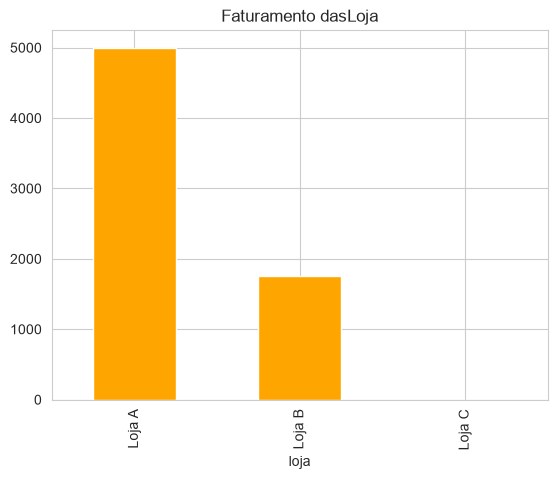

In [399]:
GraficoFaturamentoLojas = vendas.groupby('loja')['faturamento'].sum().sort_values(ascending=False)
GraficoFaturamentoLojas.plot(kind='bar', color='orange', title='Faturamento dasLoja')

<Axes: title={'center': 'Evolução do Faturamento Mensal em todas as Lojas'}, xlabel='data,loja'>

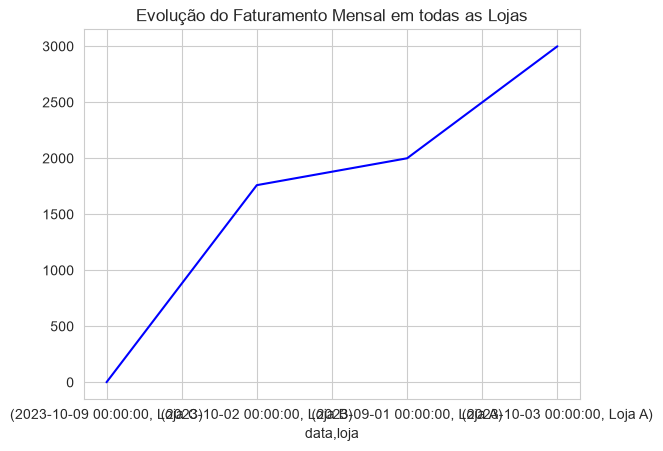

In [400]:
EvolucaoFaturamentoLojas = vendas.groupby(['data', 'loja'])['faturamento'].sum().sort_values()
EvolucaoFaturamentoLojas.plot(kind='line', color='blue', title='Evolução do Faturamento Mensal em todas as Lojas', label='Fonte: Dados de Vendas')

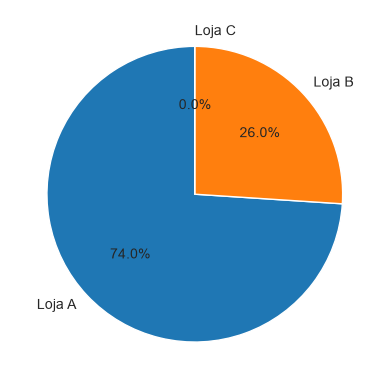

In [401]:
PorcentualFaturamentoLojas = vendas.groupby('loja')['faturamento'].sum().sort_values(ascending=False)
plt.pie(PorcentualFaturamentoLojas, labels=PorcentualFaturamentoLojas.index, autopct='%1.1f%%', startangle=90)

<Axes: xlabel='produto'>

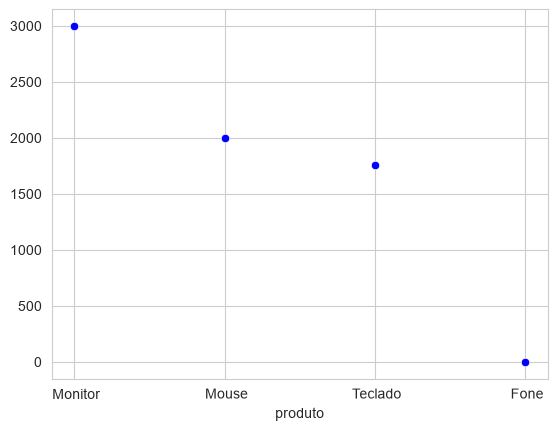

In [402]:
GraficoDispersao = vendas.groupby('produto')['faturamento'].sum().sort_values(ascending=False)
sns.scatterplot(x=GraficoDispersao.index, y=GraficoDispersao.values, color='blue')

<Axes: xlabel='produto'>

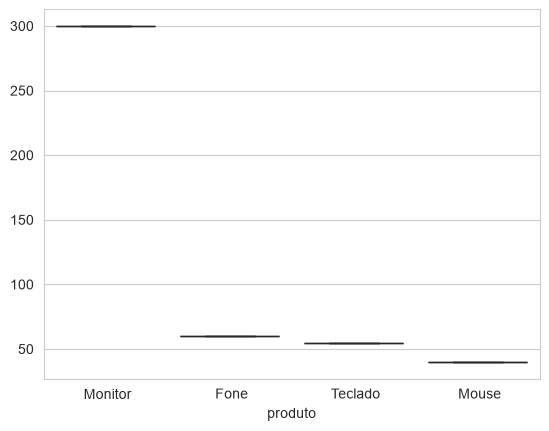

In [403]:
GraficoBoxPlotPrecoUnitario = vendas.groupby('produto')['preco_unitario'].sum().sort_values(ascending=False)
sns.boxplot(x=GraficoBoxPlotPrecoUnitario.index, y=GraficoBoxPlotPrecoUnitario.values, color='green')

<Axes: xlabel='data', ylabel='loja'>

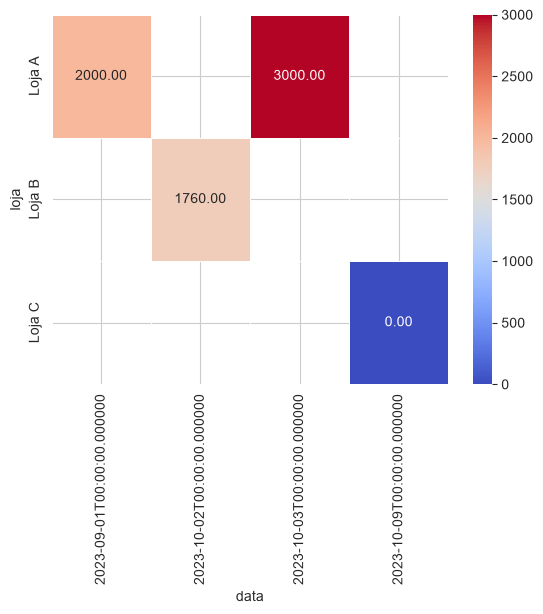

In [404]:
HeatmapDataset = vendas.pivot_table(values='faturamento', index='loja', columns='data', aggfunc='sum')
sns.heatmap(HeatmapDataset, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)